# 06 · E5: the same recipe on a random image-level split (RQ3)

**Question (RQ3).** How much does a random image-level split overestimate performance compared with a split by drive?

KITTI's images are frames from 141 drives; neighbouring frames of one drive are almost identical. A **random**
split scatters each drive over train, validation and test, so many test images have a near-copy in training.
E5 trains exactly FINAL's recipe on such a split and scores it on its own random test set; the difference to FINAL's
score on unseen drives is the over-estimate.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Settings (from notebook 04) and FINAL's result (from notebook 05)

In [2]:
import_outputs("FINAL")
choice = json.loads((RESULTS / "final_config.json").read_text())
cfg = dict(choice["config"])
rfs, IMGSZ, batch = cfg.pop("rfs", False), cfg.pop("imgsz"), cfg.pop("batch")
final_rec = load_record("FINAL")
print("FINAL test primary (unseen drives):", round(final_rec["test_primary_mAP50_mod"], 3))

imported: ['FINAL'] | missing: []
FINAL test primary (unseen drives): 0.799


## Data: the random split

The same 7 481 images; only the assignment to train / validation / test differs.

In [3]:
tables = prepare_data()
images = tables[0]
data_yaml = write_rfs_list(tables, kind="random", name="train_rfs_random.txt")[0] if rfs else \
    write_yaml(DATA, train="random_train.txt", val="random_val.txt", test="random_test.txt", name="kitti_random.yaml")
pd.crosstab(images.split_random, images.split_grouped, margins=True)

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543
RFS: 5236 training images -> 6912 per epoch


split_grouped,test,train,val,All
split_random,,,,
test,229,719,175,1123
train,1072,3305,859,5236
val,242,675,205,1122
All,1543,4699,1239,7481


## Training

In [4]:
w, info = yolo_train("E5", choice["base"], data_yaml, imgsz=IMGSZ, epochs=50, batch=batch, **cfg)
info["settings"] = json.dumps(choice["config"])
info

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
training E5: yolov8s.pt, up to 50 epochs, imgsz 960, batch 16, changes: {'lr0': 0.002}
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/train_rfs_random.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      7.63G      1.103     0.8539      1.046        194        960: 100% ━━━━━━━━━━━━ 432/432 2.5it/s 2:51
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.7it/s 6.3s
                   all       1122       6062      0.719      0.639        0.7      0.453

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      7.45G       1.03     0.7502      1.015        157        960: 100% ━━━━━━━━━━━━ 432/432 2.5it/s 2:51
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.7it/s 6.3s
                   all       1122       6062       0.76      0.723      0.772      0.524

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      7.45G     0.9891     0.6913     0.9962        157        960: 100% ━━━━━━━━━━━━ 432/432 2.5it/s 2:51
                 Class     Images  Instances      Box(P 

{'model': 'yolov8s.pt',
 'imgsz': 960,
 'batch': 16,
 'max_epochs': 50,
 'epochs_run': 50,
 'best_epoch': 50,
 'train_hours': 2.499,
 'settings': '{"imgsz": 960, "batch": 16, "rfs": true, "lr0": 0.002}',
 'data': 'train_rfs_random.yaml',
 'ultralytics_val_mAP50': 0.93956,
 'ultralytics_val_mAP50_95': 0.74525}

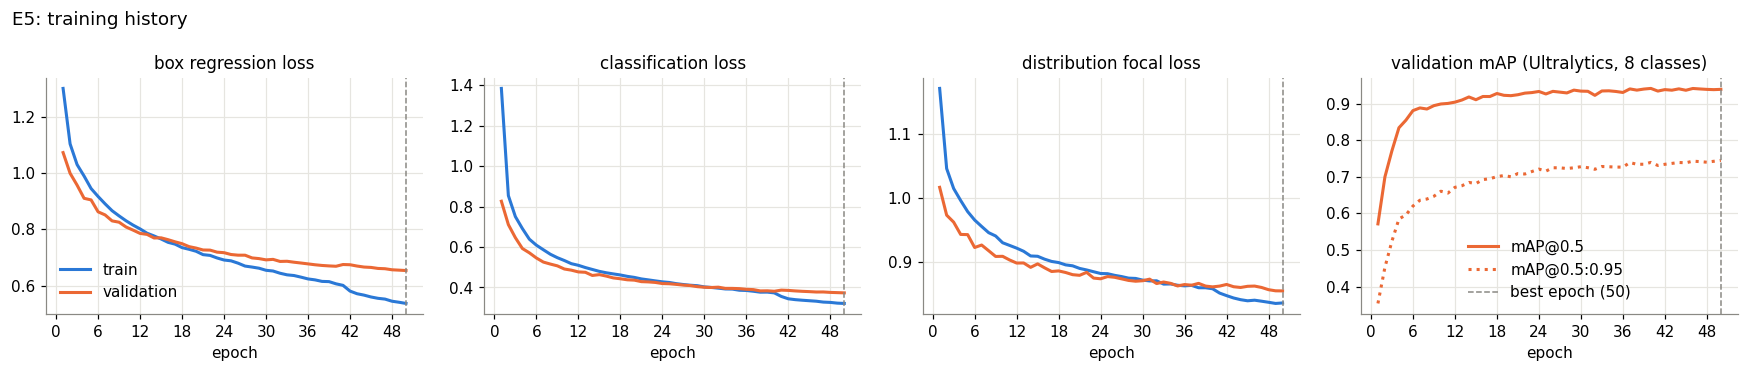

In [5]:
plot_yolo_history("E5")

## Validation and test (random split)

In [6]:
val, _, _ = evaluate_model("E5", "yolo", w, tables, "val", "random", imgsz=IMGSZ)
test, test_table, test_preds = evaluate_model("E5", "yolo", w, tables, "test", "random", imgsz=IMGSZ)
headline(**{"E5 val (random)": val, "E5 test (random)": test,
            "FINAL test (unseen drives)": {k[5:]: v for k, v in final_rec.items() if k.startswith("test_")}})

E5 on random_val:   0%|          | 0/71 [00:00<?, ?it/s]

E5 on random_test:   0%|          | 0/71 [00:00<?, ?it/s]

,E5 val (random),E5 test (random),FINAL test (unseen drives)
"Primary (Car/Ped/Cyc, Moderate)",0.947,0.964,0.799
Car,0.974,0.987,0.967
Pedestrian,0.920,0.942,0.797
Cyclist,0.947,0.963,0.631
Easy (3 classes),0.971,0.987,0.830
Hard (3 classes),0.935,0.941,0.780
Car AP@0.7,0.974,0.972,0.935
"mAP@0.5, all 8 classes",0.938,0.949,0.526
"mAP@0.5:0.95, all 8 classes",0.729,0.744,0.333


## Where does the gap come from?

For every random-split test image, the distance (in frames of the original video) to the closest **training** frame
of the same drive. Images with a training neighbour at most 2 frames away (≈ 0.2 s of driving) are near-duplicates.
If the over-estimate comes from leakage, E5 should score much higher on those.

In [7]:
images, ann, ign = tables
gaps = {}
for drive, g in images.groupby("drive"):
    tr = g.loc[g.split_random == "train", "raw_frame"].to_numpy()
    for r in g[g.split_random == "test"].itertuples():
        gaps[r.image_id] = np.abs(tr - r.raw_frame).min() if len(tr) else np.inf
gaps = pd.Series(gaps, name="frames_to_nearest_train")
gaps = gaps[gaps.index.isin(set(split_ids(images, "test", "random")))]
gaps.to_csv(exp_dir("E5") / "random_test_gap_to_train.csv")
rows = []
for name, ids in [("near-duplicate (<= 2 frames)", gaps[gaps <= 2].index), ("no close neighbour (> 2 frames)", gaps[gaps > 2].index)]:
    s, _ = Evaluator(ann, ign, list(ids)).summary(test_preds[test_preds.image_id.isin(set(ids))], with_coco_range=False)
    rows.append({"subset": name, "images": len(ids), "primary_mAP50_mod": s["primary_mAP50_mod"], "mAP50_all8": s["mAP50_all8"]})
breakdown = pd.DataFrame(rows)
breakdown.to_csv(exp_dir("E5") / "near_duplicate_breakdown.csv", index=False)
print(f"{(gaps <= 2).mean():.0%} of the random test images have a training frame within 2 frames")
breakdown.round(3)

76% of the random test images have a training frame within 2 frames


,subset,images,primary_mAP50_mod,mAP50_all8
0,near-duplicate (<= 2 frames),853,0.968,0.955
1,no close neighbour (> 2 frames),270,0.956,0.925


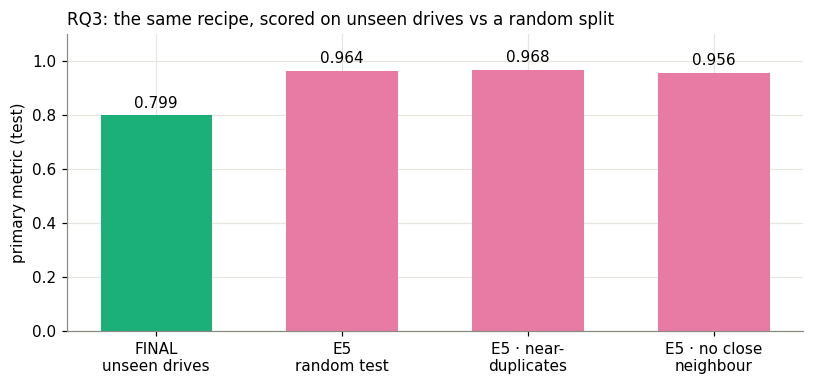

In [8]:
bars = {"FINAL\nunseen drives": final_rec["test_primary_mAP50_mod"], "E5\nrandom test": test["primary_mAP50_mod"],
        "E5 · near-\nduplicates": breakdown.primary_mAP50_mod[0], "E5 · no close\nneighbour": breakdown.primary_mAP50_mod[1]}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
b_ = ax.bar(list(bars), list(bars.values()), color=[MODEL_C["FINAL"], MODEL_C["E5"], MODEL_C["E5"], MODEL_C["E5"]], width=0.6)
ax.bar_label(b_, fmt="%.3f", padding=3); ax.set_ylim(0, 1.1); ax.set_ylabel("primary metric (test)")
ax.set_title("RQ3: the same recipe, scored on unseen drives vs a random split", loc="left")
plt.tight_layout(); fig.savefig(exp_dir("E5") / "figures" / "rq3_gap.png", dpi=130); plt.show()

## Observations

- **The random split inflates the score by 0.165:** the same recipe scores **0.964** on a random test set against
  **0.799** on unseen drives (Cyclist 0.963 vs 0.631). The number a random split reports is not what the model
  would achieve on new roads.
- **The training curve shows the leak.** On the random split, validation kept improving for all **50 epochs** (best
  epoch 50), while on the drive-grouped split it peaked at epoch 3. Memorising the training scenes is rewarded when
  validation frames come from the same drives.
- **It is not only neighbouring frames.** Random-test images within 2 frames of a training image score 0.968; those
  with no training image that close still score 0.956. The leak is at the level of whole drives (same streets,
  same cars, same lighting), which is why the split has to be grouped by drive and not just thinned out.

## Record

In [9]:
rec = save_record("E5", "FINAL recipe on the random image-level split", "RQ3", val=val, test=test, eval_split="random", **info)
pd.Series(rec).to_frame("value")

,value
exp_id,E5
description,FINAL recipe on the random image-level split
research_question,RQ3
eval_split,random
model,yolov8s.pt
imgsz,960
batch,16
max_epochs,50
epochs_run,50
best_epoch,50
